# Comparação de imagens

Este notebook compara **duas imagens escolhidas manualmente** ou **todas as imagens correspondentes de dois diretórios**.

As imagens são carregadas em escala de cinza. O notebook calcula pixels iguais/diferentes, percentual de igualdade, MAE, RMSE e erro máximo, além de exibir a comparação visual.

## 1. Configuração

In [5]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Escolha: "individual" ou "diretorios"
MODO_COMPARACAO = "diretorios"

# Modo individual: informe os caminhos de quaisquer duas imagens.
IMAGEM_A = Path("../results/stm32/bird_stm32.pgm")
IMAGEM_B = Path("../results/reference/bird_kornia.pgm")

# Modo diretórios: compara arquivos com o mesmo caminho relativo/nome.
STM_DIR = Path("../results/stm32")
REFERENCE_DIR = Path("../results/reference")

# Imagem exibida na comparação visual:
# "primeira" mostra o primeiro par validado; ou informe a chave/nome do par.
IMAGEM_PARA_EXIBIR = "primeira"

## 2. Funções de leitura e comparação

In [6]:
def ler_imagem(caminho):
    """Lê uma imagem em escala de cinza."""
    caminho = Path(caminho)
    imagem = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)

    if imagem is None:
        raise ValueError(f"Não foi possível ler a imagem: {caminho.resolve()}")

    return imagem


def comparar_imagens(caminho_a, caminho_b):
    """Compara duas imagens e retorna métricas e matrizes para visualização."""
    imagem_a = ler_imagem(caminho_a)
    imagem_b = ler_imagem(caminho_b)

    if imagem_a.shape != imagem_b.shape:
        raise ValueError(
            f"Dimensões diferentes: {Path(caminho_a).name} tem "
            f"{imagem_a.shape[1]}x{imagem_a.shape[0]}, enquanto "
            f"{Path(caminho_b).name} tem {imagem_b.shape[1]}x{imagem_b.shape[0]}."
        )

    diferenca = np.abs(
        imagem_a.astype(np.int16) - imagem_b.astype(np.int16)
    )

    total_pixels = int(diferenca.size)
    pixels_iguais = int(np.count_nonzero(diferenca == 0))
    pixels_diferentes = total_pixels - pixels_iguais

    return {
        "imagem_a": imagem_a,
        "imagem_b": imagem_b,
        "diferenca": diferenca,
        "total_pixels": total_pixels,
        "pixels_iguais": pixels_iguais,
        "pixels_diferentes": pixels_diferentes,
        "percentual_igual": (pixels_iguais / total_pixels * 100) if total_pixels else 0.0,
        "mae": float(np.mean(diferenca)) if total_pixels else 0.0,
        "rmse": float(np.sqrt(np.mean(diferenca.astype(np.float64) ** 2))) if total_pixels else 0.0,
        "erro_maximo": int(np.max(diferenca)) if total_pixels else 0,
    }

## 3. Selecionar os pares de imagens

In [7]:
def listar_pares_diretorios(diretorio_a, diretorio_b, recursivo=False):
    diretorio_a = Path(diretorio_a)
    diretorio_b = Path(diretorio_b)

    if not diretorio_a.is_dir():
        raise FileNotFoundError(f"Diretório A não encontrado: {diretorio_a.resolve()}")
    if not diretorio_b.is_dir():
        raise FileNotFoundError(f"Diretório B não encontrado: {diretorio_b.resolve()}")

    glob = "**/*.pgm" if recursivo else "*.pgm"
    arquivos_a = {p.relative_to(diretorio_a): p for p in diretorio_a.glob(glob) if p.is_file()}
    arquivos_b = {p.relative_to(diretorio_b): p for p in diretorio_b.glob(glob) if p.is_file()}

    chaves_comuns = sorted(set(arquivos_a) & set(arquivos_b), key=lambda p: str(p).lower())
    somente_a = sorted(set(arquivos_a) - set(arquivos_b), key=lambda p: str(p).lower())
    somente_b = sorted(set(arquivos_b) - set(arquivos_a), key=lambda p: str(p).lower())

    if somente_a:
        print("Arquivos sem correspondente no diretório B:")
        for nome in somente_a:
            print(f"  A: {nome}")
    if somente_b:
        print("Arquivos sem correspondente no diretório A:")
        for nome in somente_b:
            print(f"  B: {nome}")

    return [(str(nome), arquivos_a[nome], arquivos_b[nome]) for nome in chaves_comuns]


if MODO_COMPARACAO == "individual":
    if not Path(IMAGEM_A).is_file():
        raise FileNotFoundError(f"Imagem A não encontrada: {Path(IMAGEM_A).resolve()}")
    if not Path(IMAGEM_B).is_file():
        raise FileNotFoundError(f"Imagem B não encontrada: {Path(IMAGEM_B).resolve()}")

    pares = [(f"{Path(IMAGEM_A).name} ↔ {Path(IMAGEM_B).name}", Path(IMAGEM_A), Path(IMAGEM_B))]

elif MODO_COMPARACAO == "diretorios":
    pares = listar_pares_diretorios(STM_DIR, REFERENCE_DIR)

else:
    raise ValueError("MODO_COMPARACAO deve ser 'individual' ou 'diretorios'.")

if not pares:
    raise RuntimeError("Nenhum par de imagens para comparar.")

print(f"Modo: {MODO_COMPARACAO}")
print(f"Pares encontrados: {len(pares)}")
for nome, caminho_a, caminho_b in pares:
    print(f"- {nome}: {caminho_a} ↔ {caminho_b}")

Modo: diretorios
Pares encontrados: 9
- bird.pgm: ../results/stm32/bird.pgm ↔ ../results/reference/bird.pgm
- boat.pgm: ../results/stm32/boat.pgm ↔ ../results/reference/boat.pgm
- bridge.pgm: ../results/stm32/bridge.pgm ↔ ../results/reference/bridge.pgm
- cameraman.pgm: ../results/stm32/cameraman.pgm ↔ ../results/reference/cameraman.pgm
- goldhill.pgm: ../results/stm32/goldhill.pgm ↔ ../results/reference/goldhill.pgm
- lena.pgm: ../results/stm32/lena.pgm ↔ ../results/reference/lena.pgm
- pirate.pgm: ../results/stm32/pirate.pgm ↔ ../results/reference/pirate.pgm
- washsat.pgm: ../results/stm32/washsat.pgm ↔ ../results/reference/washsat.pgm
- zelda.pgm: ../results/stm32/zelda.pgm ↔ ../results/reference/zelda.pgm


## 4. Executar as comparações

In [8]:
comparacoes = {}
linhas_resultados = []
erros = []

for nome, caminho_a, caminho_b in pares:
    try:
        resultado = comparar_imagens(caminho_a, caminho_b)
        comparacoes[nome] = {
            **resultado,
            "caminho_a": str(caminho_a),
            "caminho_b": str(caminho_b),
        }

        linhas_resultados.append({
            "Par": nome,
            "Imagem A": str(caminho_a),
            "Imagem B": str(caminho_b),
            "Dimensões": f"{resultado['imagem_a'].shape[1]}x{resultado['imagem_a'].shape[0]}",
            "Pixels iguais": resultado["pixels_iguais"],
            "Pixels diferentes": resultado["pixels_diferentes"],
            "% de igualdade": resultado["percentual_igual"],
            "MAE": resultado["mae"],
            "RMSE": resultado["rmse"],
            "Erro máximo": resultado["erro_maximo"],
        })
    except Exception as exc:
        erros.append((nome, str(exc)))
        print(f"[ERRO] {nome}: {exc}")

if not linhas_resultados:
    raise RuntimeError("Nenhum par pôde ser comparado. Confira os caminhos e as dimensões.")

df_resultados = pd.DataFrame(linhas_resultados)
display(df_resultados)

if erros:
    print(f"\nPares com erro: {len(erros)}")

,Par,Imagem A,Imagem B,Dimensões,Pixels iguais,Pixels diferentes,% de igualdade,MAE,RMSE,Erro máximo
0,bird.pgm,../results/stm32/bird.pgm,../results/reference/bird.pgm,90x90,8100,0,100.0,0.0,0.0,0
1,boat.pgm,../results/stm32/boat.pgm,../results/reference/boat.pgm,90x90,8100,0,100.0,0.0,0.0,0
2,bridge.pgm,../results/stm32/bridge.pgm,../results/reference/bridge.pgm,90x90,8100,0,100.0,0.0,0.0,0
3,cameraman.pgm,../results/stm32/cameraman.pgm,../results/reference/cameraman.pgm,90x90,8100,0,100.0,0.0,0.0,0
4,goldhill.pgm,../results/stm32/goldhill.pgm,../results/reference/goldhill.pgm,90x90,8100,0,100.0,0.0,0.0,0
5,lena.pgm,../results/stm32/lena.pgm,../results/reference/lena.pgm,90x90,8100,0,100.0,0.0,0.0,0
6,pirate.pgm,../results/stm32/pirate.pgm,../results/reference/pirate.pgm,90x90,8100,0,100.0,0.0,0.0,0
7,washsat.pgm,../results/stm32/washsat.pgm,../results/reference/washsat.pgm,90x90,8100,0,100.0,0.0,0.0,0
8,zelda.pgm,../results/stm32/zelda.pgm,../results/reference/zelda.pgm,90x90,8100,0,100.0,0.0,0.0,0


## 5. Comparação visual

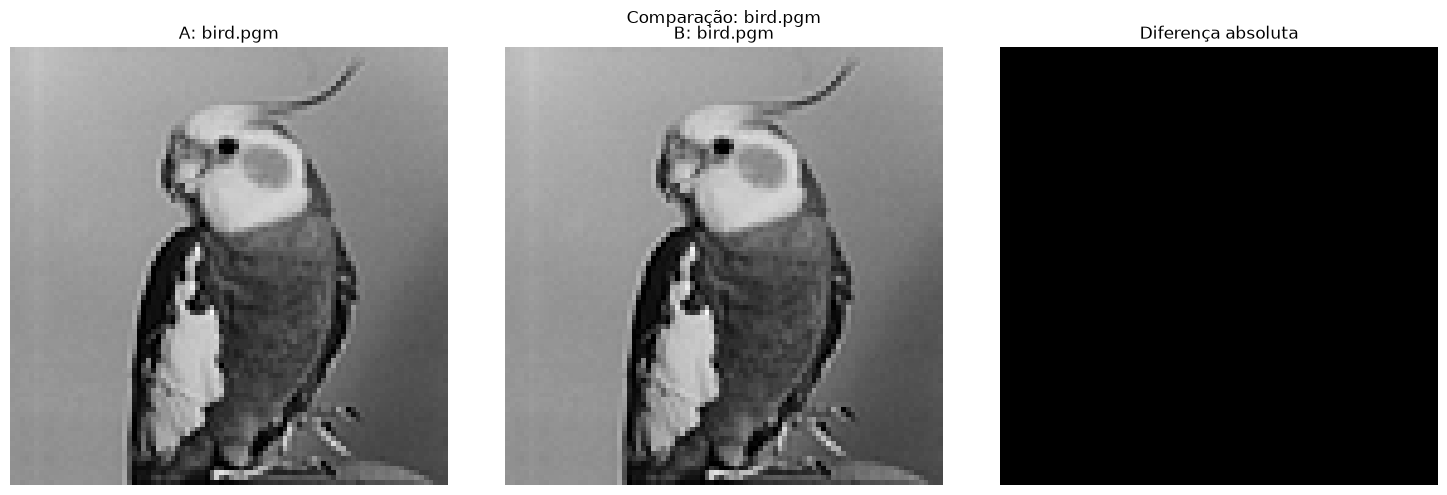

In [9]:
if IMAGEM_PARA_EXIBIR == "primeira":
    nome_visual = next(iter(comparacoes))
else:
    correspondencias = [
        nome for nome in comparacoes
        if nome == IMAGEM_PARA_EXIBIR
        or Path(comparacoes[nome]["caminho_a"]).name == IMAGEM_PARA_EXIBIR
    ]
    if not correspondencias:
        raise KeyError(
            f"Não encontrei '{IMAGEM_PARA_EXIBIR}'. "
            f"Opções: {list(comparacoes.keys())}"
        )
    nome_visual = correspondencias[0]

resultado = comparacoes[nome_visual]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(resultado["imagem_a"], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"A: {Path(resultado['caminho_a']).name}")
axes[1].imshow(resultado["imagem_b"], cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"B: {Path(resultado['caminho_b']).name}")
axes[2].imshow(
    resultado["diferenca"],
    cmap="gray",
    vmin=0,
    vmax=max(1, resultado["erro_maximo"]),
)
axes[2].set_title("Diferença absoluta")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Comparação: {nome_visual}")
plt.tight_layout()
plt.show()

## 6. Resumo geral e exportação

In [11]:
total_imagens = len(comparacoes)
total_pixels = sum(r["total_pixels"] for r in comparacoes.values())
pixels_iguais = sum(r["pixels_iguais"] for r in comparacoes.values())
pixels_diferentes = sum(r["pixels_diferentes"] for r in comparacoes.values())
imagens_identicas = sum(r["erro_maximo"] == 0 for r in comparacoes.values())

percentual_global = pixels_iguais / total_pixels * 100 if total_pixels else 0.0
maior_erro = max(r["erro_maximo"] for r in comparacoes.values())

print("=" * 52)
print("RESUMO DA COMPARAÇÃO")
print("=" * 52)
print(f"Modo:                     {MODO_COMPARACAO}")
print(f"Pares comparados:         {total_imagens}")
print(f"Pares idênticos:          {imagens_identicas}")
print(f"Pares diferentes:         {total_imagens - imagens_identicas}")
print(f"Pixels comparados:        {total_pixels}")
print(f"Pixels iguais:            {pixels_iguais}")
print(f"Pixels diferentes:        {pixels_diferentes}")
print(f"Percentual global igual:  {percentual_global:.4f}%")
print(f"Maior erro encontrado:    {maior_erro}")
print("=" * 52)

RESUMO DA COMPARAÇÃO
Modo:                     diretorios
Pares comparados:         9
Pares idênticos:          9
Pares diferentes:         0
Pixels comparados:        72900
Pixels iguais:            72900
Pixels diferentes:        0
Percentual global igual:  100.0000%
Maior erro encontrado:    0
